In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.tree import DecisionTreeClassifier



In [ ]:
wine_data = pd.read_csv('winequality-red.csv')

In [7]:
wine_data.shape

(1599, 12)

In [8]:
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [9]:
wine_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [10]:
wine_data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

<Axes: xlabel='quality', ylabel='count'>

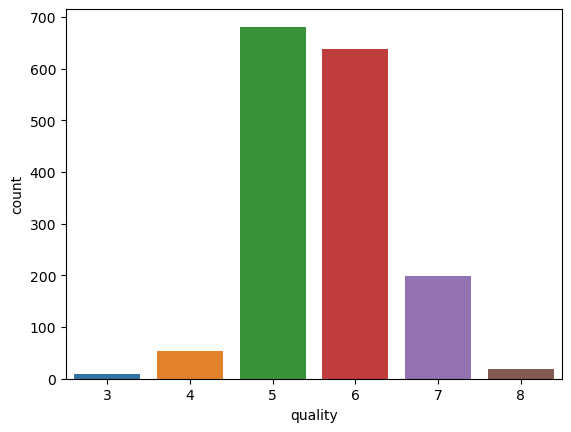

In [11]:
sns.countplot(x='quality',data=wine_data)

<Axes: xlabel='quality', ylabel='volatile acidity'>

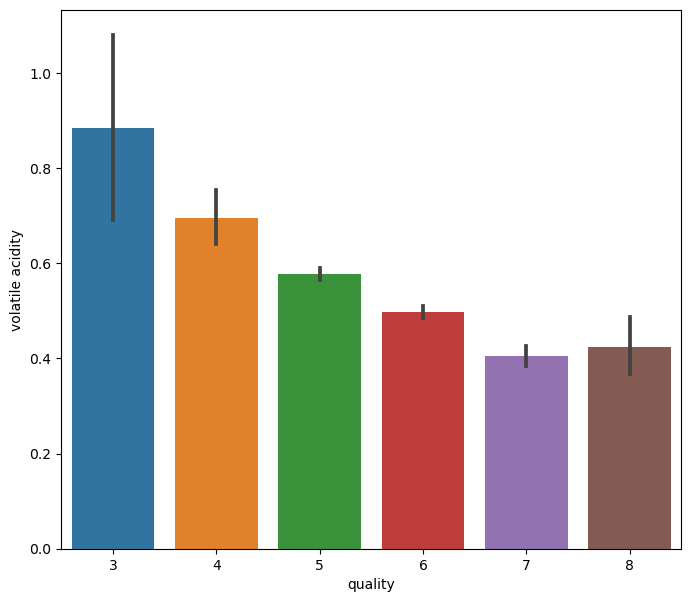

In [12]:
plt.figure(figsize=(8,7))
sns.barplot(x='quality',y='volatile acidity',data=wine_data)

<Axes: xlabel='quality', ylabel='citric acid'>

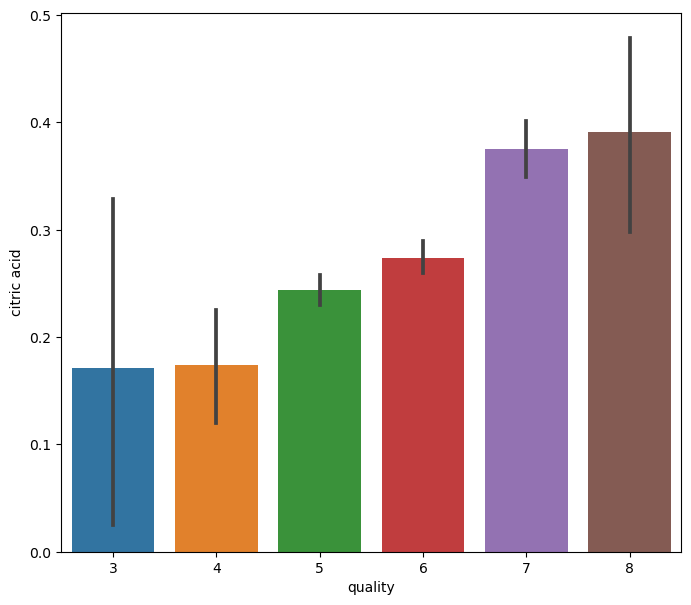

In [13]:
plt.figure(figsize=(8,7))
sns.barplot(x='quality',y='citric acid',data=wine_data)

In [14]:
correlation = wine_data.corr()

<Axes: >

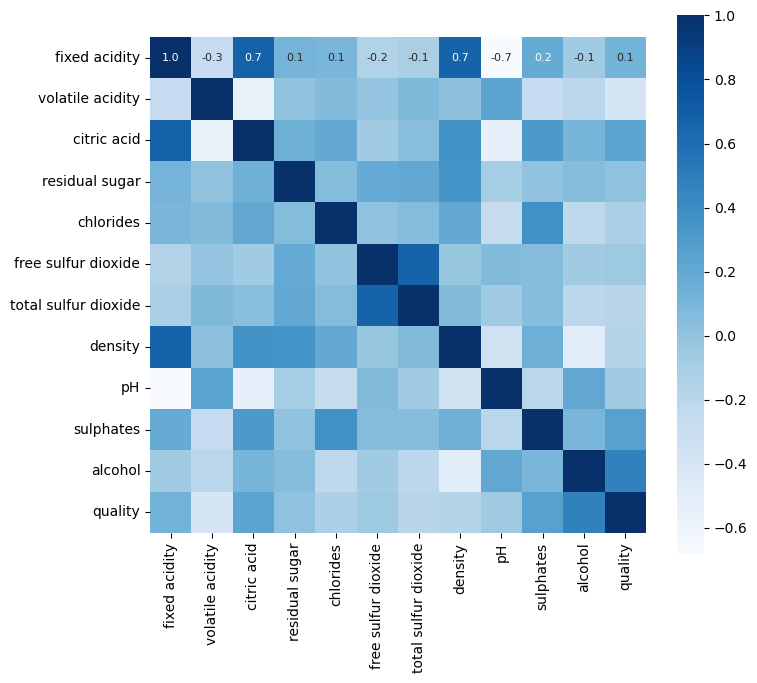

In [15]:
plt.figure(figsize=(8,7))
sns.heatmap(correlation,cbar=True,square=True,fmt='.1f',annot=True,annot_kws={'size':8},cmap='Blues')

In [16]:
x= wine_data.drop('quality',axis=1)

In [17]:
y= wine_data['quality'].apply(lambda y_value:1 if y_value >= 7 else 0)

In [18]:
print(y)

0       0
1       0
2       0
3       0
4       0
       ..
1594    0
1595    0
1596    0
1597    0
1598    0
Name: quality, Length: 1599, dtype: int64


In [ ]:
X_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state= 2)


In [20]:
model= RandomForestClassifier()
model.fit(X_train,y_train)

RandomForestClassifier()

In [21]:
pred = model.predict(x_test)
acc = accuracy_score(pred,y_test)
conf_matrix = confusion_matrix(pred,y_test)

In [29]:
print(acc)
print(conf_matrix)

0.915625
[[270  18]
 [  9  23]]


In [32]:
parameter = {'max_depth':[5,10,15,17,20,25,None],'n_estimators':[30,50,70,100],'min_samples_split': [2, 5, 10]}

In [33]:
from sklearn.model_selection import GridSearchCV
searchcv = GridSearchCV(RandomForestClassifier(random_state=42),param_grid=parameter,cv=5,n_jobs=-1,scoring='accuracy')

In [34]:
searchcv.fit(X_train,y_train)


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [5, 10, 15, 17, 20, 25, None],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [30, 50, 70, 100]},
             scoring='accuracy')

In [35]:
pred_test = searchcv.predict(x_test)

In [36]:
searchcv.best_params_

{'max_depth': 17, 'min_samples_split': 2, 'n_estimators': 50}

In [37]:
score = accuracy_score(pred_test,y_test)
confu_matrix = confusion_matrix(pred_test,y_test)

In [38]:
print(score)
print(confu_matrix)

0.925
[[269  14]
 [ 10  27]]


In [39]:
rfc_eval = cross_val_score(estimator =searchcv, X = X_train, y = y_train, cv = 10)
rfc_eval.mean()

0.9030634842519685